# Generating Synthetic Videos

How `tools/` builds a synthetic chromatin-motion video with a known
ground-truth flow, from a real cell video: pick a random frame, segment the
cell, then simulate a compressible, viscous velocity field confined to the
cell mask and advect the frame's density by it. This is the exact process
that generated the paper's SynthCells dataset (the `SynthCells_sample.zip`
bundled in `Datasets/`).

Uses the real video already bundled in `Datasets/RealCells_sample.zip`
(`complete_sample_video/`), a fixed seed for the random frame, and SAM 2 by
default for segmentation (itself seeded by a Hough circle fit -- see
`tools/segmentation.py`) -- falling back to Hough alone if no checkpoint is
configured, so this notebook still runs either way. Run it from the
`tools/` folder.

In [1]:
import os
import sys
import zipfile

sys.path.insert(0, os.path.abspath("."))

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.titlesize"] = 11

from configs import default_params as config
from generate_synthetic_video import run_simulation
from segmentation import SAM2VideoSegmenter, segment_cell
from video_io import get_random_frame

SEED = 42
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

/home/migueldi/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Step 1 -- Get a real cell frame

`Datasets/RealCells_sample.zip` ships one complete, untouched real video
(`complete_sample_video/`, see its own `README.txt`) alongside the curated
pairs used elsewhere in this repo. We extract it once, then pick a random
frame from it with a fixed seed -- `get_random_frame` reproducibly selects
both the video's random frame *and* (inside `run_simulation`, below) the
random motion field, so the whole simulation is exactly reproducible.

7_Patient_1573_(LLA_T)_241003-patient-1573_(LT)_20241003_192218_231_Point0001_ChannelBF1-ROI_Seq0005.mp4: picked a random frame (seed=42), shape (166, 166, 3)


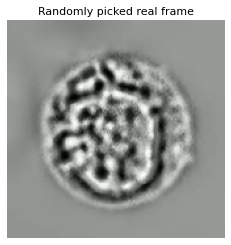

In [2]:
with zipfile.ZipFile("../Datasets/RealCells_sample.zip") as zf:
    video_name = next(n for n in zf.namelist()
                       if n.startswith("complete_sample_video/") and n.endswith(".mp4"))
    zf.extract(video_name, OUTPUT_DIR)
VIDEO_PATH = os.path.join(OUTPUT_DIR, video_name)

seed_frame = get_random_frame(VIDEO_PATH, seed=SEED)
print(f"{os.path.basename(VIDEO_PATH)}: picked a random frame (seed={SEED}), "
      f"shape {seed_frame.shape}")

plt.figure(figsize=(4, 4))
plt.imshow(cv2.cvtColor(seed_frame, cv2.COLOR_BGR2RGB))
plt.title("Randomly picked real frame")
plt.axis("off")
plt.show()

## Step 2 -- Segment the cell

The physics in `physics.py` is confined to this mask: it is both where the
random/turbulent velocity field is allowed to act and the boundary that
stops density from being pushed out through the membrane.

[SAM 2] Loading predictor on CUDA...
[SAM 2] Ready.


frame loading (JPEG): 100%|██████████| 1/1 [00:00<00:00, 18.92it/s]
/tmp/sam2_pkg/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/tmp/sam2_pkg/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video:   0%|          | 0/1 [00:00<?, ?it/s]

Segmentation method used: sam


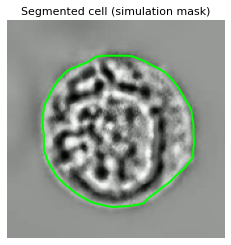

In [3]:
sam = None
if config.SEGMENTATION_METHOD == "sam":
    try:
        sam = SAM2VideoSegmenter(config.SAM_MODEL_CONFIG, config.SAM_CHECKPOINT, config.SAM_DEVICE)
    except Exception as e:
        print(f"[!] SAM 2 not available ({e}); falling back to Hough.")

mask = segment_cell(seed_frame, OUTPUT_DIR, sam=sam)
print(f"Segmentation method used: {'sam' if sam is not None else 'hough'}")

plt.figure(figsize=(4, 4))
plt.imshow(cv2.cvtColor(seed_frame, cv2.COLOR_BGR2RGB))
plt.contour(mask, levels=[0.5], colors="lime", linewidths=2)
plt.title("Segmented cell (simulation mask)")
plt.axis("off")
plt.show()

## Step 3 -- Simulate

`run_simulation` resizes the frame to `config.TARGET_SIZE`, builds a
density field from it (chromatin is dark, so density = 1 - intensity), and
for `config.FRAMES_PER_SIM` steps: generates a random velocity field
confined to the mask (weighted mix of density-gradient-following and
turbulent components, Gaussian-smoothed by `config.VISCOSITY`), then
advects the density by it (`physics.py`'s `advect_density_compressible`,
a compressible semi-Lagrangian warp). Each step is saved as an
`(img_t, img_tp1, flow)` triplet, plus one `mask.npy` for the whole
simulation (the cell mask is the same every step) -- exactly the format
`Datasets/SynthCells_sample.zip`'s pairs are in
(`gt['u_gt']`/`gt['v_gt']`/`gt['mask']`).

In [4]:
sim_dir = os.path.join(OUTPUT_DIR, "sim_00")
run_simulation(VIDEO_PATH, sim_dir, frames=config.FRAMES_PER_SIM, sam=sam, seed=SEED)
print(f"Generated {config.FRAMES_PER_SIM} frames -> {sim_dir}/")

propagate in video:   0%|          | 0/1 [00:00<?, ?it/s]


Generated 200 frames -> output/sim_00/


### The result: frame 0 vs. frame 199

Any single step's motion is subtle by design (`config.INTENSITY = 0.35`,
smoothed by `config.VISCOSITY = 4.0`) -- it's meant to resemble real
chromatin motion, not a dramatic flow. It accumulates into a visible
deformation only over the full 200 frames.

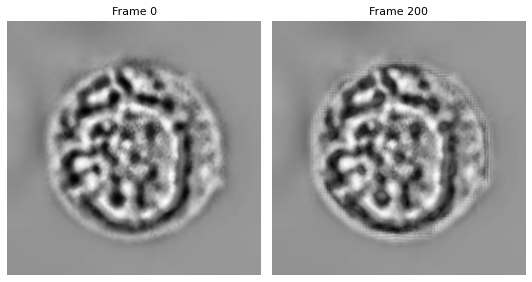

In [5]:
last = config.FRAMES_PER_SIM - 1
img_first = cv2.imread(os.path.join(sim_dir, "img_t_000.tiff"), cv2.IMREAD_UNCHANGED)
img_last = cv2.imread(os.path.join(sim_dir, f"img_tp1_{last:03d}.tiff"), cv2.IMREAD_UNCHANGED)
flow_last = np.load(os.path.join(sim_dir, f"flow_{last:03d}.npy"))  # (2, H, W) -> [U, V]

fig, axes = plt.subplots(1, 2, figsize=(7.5, 4))
axes[0].imshow(img_first, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Frame 0")
axes[1].imshow(img_last, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Frame {config.FRAMES_PER_SIM}")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

### The ground-truth flow: dense map + zoom

Same visual convention as `compflow_demo.ipynb`'s (`utils.py`): direction as
hue (dense, every mask pixel) on the full cell, and a small zoomed-in crop
with the same per-pixel vectors drawn as colored arrows -- the only way to
actually see individual vectors at this resolution.

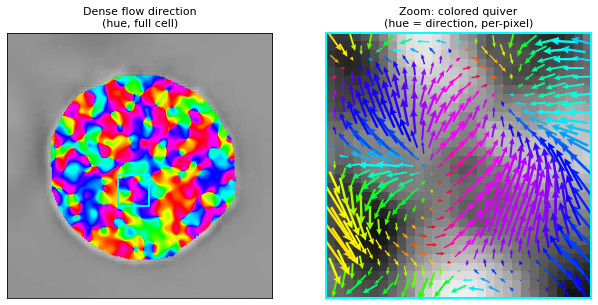

In [6]:
sys.path.insert(0, os.path.abspath(".."))  # repo root -- for utils.py, shared with compflow_demo.ipynb
from matplotlib.patches import Rectangle
from utils import colored_quiver, dense_direction_map, pick_zoom_regions

img_last_u8 = (img_last * 255).astype(np.uint8)
# Loaded from disk rather than reusing Step 2's `mask` variable -- this is
# the one run_simulation() actually used (already resized to
# config.TARGET_SIZE, matching img_last/flow_last), and it's what anyone
# loading this simulation's output later would use too.
mask_bin = np.load(os.path.join(sim_dir, "mask.npy"))

dense_rgb, dense_vis = dense_direction_map(flow_last[0], flow_last[1], mask_bin, img_last_u8, threshold=0.0)

ZOOM = 30
(y0, x0), = pick_zoom_regions(mask_bin, size=ZOOM, n=1, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.3))

axes[0].imshow(img_last_u8, cmap="gray", vmin=0, vmax=255)
axes[0].imshow(np.concatenate([dense_rgb, dense_vis[..., None].astype(np.float32)], axis=-1))
axes[0].add_patch(Rectangle((x0, y0), ZOOM, ZOOM, fill=False, edgecolor="cyan", linewidth=1.8))
axes[0].set_title("Dense flow direction\n(hue, full cell)")

ext = (x0, x0 + ZOOM, y0 + ZOOM, y0)
axes[1].imshow(img_last_u8[y0:y0 + ZOOM, x0:x0 + ZOOM], cmap="gray", vmin=0, vmax=255, extent=ext)
colored_quiver(axes[1], flow_last[0], flow_last[1], mask_bin, y0, x0, ZOOM, step=2.0, scale=30.0, width=0.005)
axes[1].set_xlim(ext[0], ext[1])
axes[1].set_ylim(ext[2], ext[3])
for sp in axes[1].spines.values():
    sp.set_edgecolor("cyan")
    sp.set_linewidth(2)
axes[1].set_title("Zoom: colored quiver\n(hue = direction, per-pixel)")

for ax in axes:
    ax.set_facecolor("black")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

In [7]:
from IPython.display import Video

Video(os.path.join(sim_dir, "sim.mp4"), embed=True, width=260)

## Using these pairs

`flow_NNN.npy` is exact, dense ground truth -- load an `(img_t, img_tp1,
flow, mask)` set the same way `Datasets/load_sample.py` reads
`SynthCells_sample.zip` (`gt['u_gt']`/`gt['v_gt']`/`gt['mask']`), run any
method from `CompFlow/` or `Comparison_methods/` on the pair, and compare
against `flow[0]`/`flow[1]` with `Metrics/aepe.py` -- **pass `mask.npy`
to it.** Ground truth is exactly zero in the background by construction,
and most methods are comparatively bad at estimating "zero" in a
textureless region, so skipping the mask can inflate a method's error by
an order of magnitude for reasons that have nothing to do with its
accuracy on the actual motion (a cross-correlation/PIV method being the
most affected in practice).

For a whole batch instead of one simulation, see `generate_synthetic_video.py`'s
`main()` (edit `configs/default_params.py`'s `INPUT_VIDEO` / `OUTPUT_DIR`,
then `python3 generate_synthetic_video.py`).